# 04 — Production costs and prices of second-season maize (Paraná)

Builds the economic basis of the article, in **BRL (R$) of December 2025** (monthly IPCA):

1. **Cost** — SEAB/DERAL "Milho Safrinha" series (`nhistorico_94.xls`, seasons 1999/00–2024/25),
   in R$ per 60-kg bag, converted to R$/ha with the reference yield reported by DERAL itself.
2. **Operating cost** — total cost minus the Factor Income (imputed remuneration of land and own
   capital). The historical DERAL series does not separate this item; its share comes from the CONAB
   series for Paraná (`milho_2a_safra_serie_historica_2005-2025.xls`), year by year.
3. **Cost structure** — how much of the cost grows with production (per kg) and how much is spent per
   hectare at sowing, from the DERAL item breakdown (`custos.xlsx`).
4. **Price** — monthly price received by farmers in Paraná (SEAB/DERAL via Ipeadata), deflated month
   by month, so that each sowing date gets the price of its harvest month (notebook 05).

**Year convention**: everything is indexed by the **harvest year** of the second season. DERAL labels by
agricultural year ("1999/00" = sown and harvested in 2000); CONAB already uses the harvest year
("SAFRA DA SECA - 2010", "2ª SAFRA 2025").

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 16})

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
RESULTADOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

BASE = (2025, 12)  # reference month of real values

## 1. Deflator — monthly IPCA

In [2]:
ipca = pd.read_csv(DADOS / "ipca_mensal.csv")  # BCB/SGS series 433, index base Dec/1998 = 100
ipca = ipca.set_index(["ano", "mes"])["indice"]
indice_base = ipca.loc[BASE]


def deflator(ano, mes):
    return indice_base / ipca.loc[(ano, mes)]


print(f"IPCA available: {ipca.index.min()} to {ipca.index.max()}; base = {BASE}")

IPCA available: (np.int64(1999), np.int64(1)) to (np.int64(2026), np.int64(5)); base = (2025, 12)


## 2. DERAL cost (R$/ha, real)

DERAL publishes the cost per bag and reports, in the spreadsheet footnote, the reference yield of each
period (60, 80, 75, 70 and 80 bags/ha). The cost per hectare is the cost per bag × that yield. Each
estimate has a **reference month** (e.g. Nov/99), used for deflation.

In [3]:
bruto = pd.read_excel(DADOS / "nhistorico_94.xls", sheet_name="milho_saf", header=None)
deral = bruto.iloc[7:33, [0, 1, 2, 3]].copy()
deral.columns = ["safra", "mes_ref", "var_60kg_nominal", "total_60kg_nominal"]
deral["ano"] = deral["safra"].str.slice(0, 4).astype(int) + 1  # harvest year

MESES = {"jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
         "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12}


def ler_mes_ref(v):
    if isinstance(v, pd.Timestamp) or hasattr(v, "year"):
        return v.year, v.month
    m = re.match(r"([a-z]{3})\D*(\d{2})", str(v).strip().lower())
    return 2000 + int(m.group(2)) if int(m.group(2)) < 50 else 1900 + int(m.group(2)), MESES[m.group(1)]


deral[["ano_ref", "mes_ref"]] = deral["mes_ref"].apply(lambda v: pd.Series(ler_mes_ref(v)))


def produtividade_referencia_sc(ano_colheita):  # DERAL spreadsheet footnote
    safra_inicio = ano_colheita - 1
    if safra_inicio <= 2003:
        return 60
    if safra_inicio <= 2005:
        return 80
    if safra_inicio == 2006:
        return 75
    if safra_inicio <= 2014:
        return 70
    return 80


deral["prod_ref_kg_ha"] = deral["ano"].map(produtividade_referencia_sc) * 60
deral["fator_deflator"] = [deflator(a, m) for a, m in zip(deral["ano_ref"], deral["mes_ref"])]
for tipo in ["var", "total"]:
    deral[f"custo_{tipo}_real_ha"] = (
        deral[f"{tipo}_60kg_nominal"].astype(float) * deral["prod_ref_kg_ha"] / 60 * deral["fator_deflator"]
    )
deral[["safra", "ano", "ano_ref", "mes_ref", "prod_ref_kg_ha", "custo_var_real_ha", "custo_total_real_ha"]].round(1)

,safra,ano,ano_ref,mes_ref,prod_ref_kg_ha,custo_var_real_ha,custo_total_real_ha
7,1999/00,2000,1999,11,3600,1817.2,2832.7
8,2000/01,2001,2000,11,3600,1810.2,2906.3
9,2001/02,2002,2001,5,3600,1811.1,2900.8
10,2002/03,2003,2002,12,3600,1818.4,3138.1
11,2003/04,2004,2003,11,3600,2082.9,3633.0
12,2004/05,2005,2004,11,4800,1999.6,3660.5
13,2005/06,2006,2005,11,4800,2203.7,3790.9
14,2006/07,2007,2006,11,4500,1745.2,3178.9
15,2007/08,2008,2007,11,4200,1754.5,3178.3
16,2008/09,2009,2008,11,4200,2242.0,3894.7


## 3. Factor Income / Total Cost — CONAB series (Paraná)

In each Paraná sheet (6 municipalities), finds the rows "Total de Renda de Fatores" and "Custo Total"
and takes the first numeric value (R$/ha). The share column (%) of the spreadsheet is not used because
its scale changes between layouts. The share of a year is the mean of the available municipalities.

In [4]:
xls = pd.ExcelFile(DADOS / "milho_2a_safra_serie_historica_2005-2025.xls")
PADRAO = re.compile(r"^(.*)-PR-(\d{4})$")


def valor_do_rotulo(linha, prefixo):
    """First number to the right of the cell whose text starts with `prefixo` (the layout changes between years)."""
    for j, v in enumerate(linha):
        if isinstance(v, str) and v.strip().upper().startswith(prefixo):
            for w in linha[j + 1:]:
                if isinstance(w, (int, float)) and pd.notna(w):
                    return float(w)
    return None


registros = []
for aba in xls.sheet_names:
    m = PADRAO.match(aba)
    if not m:
        continue
    df = xls.parse(aba, header=None)
    rf = ct = np.nan
    for linha in df.itertuples(index=False):
        linha = list(linha)
        rf = valor_do_rotulo(linha, "TOTAL DE RENDA DE FATORES") or rf
        ct = valor_do_rotulo(linha, "CUSTO TOTAL") or ct
    registros.append({"cidade": m.group(1), "ano": int(m.group(2)), "renda_fatores": rf, "custo_total": ct})

conab = pd.DataFrame(registros)
conab["ratio"] = conab["renda_fatores"] / conab["custo_total"]
print("Sheets not read:", conab["ratio"].isna().sum(), "of", len(conab))
ratio_rf = conab.groupby("ano")["ratio"].agg(["mean", "std", "count"])
ratio_rf.round(3).T

Sheets not read: 4 of 85


ano,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
mean,0.212,0.184,0.189,0.220,0.192,0.186,0.190,0.193,0.187,0.171,...,0.322,0.341,0.367,0.218,0.195,0.062,0.16,0.309,0.286,0.278
std,0.031,NaN,NaN,0.063,0.075,0.069,0.058,0.068,0.066,0.036,...,0.064,0.069,0.024,0.018,0.039,0.018,0.05,0.085,0.060,0.060
count,2.000,1.000,1.000,2.000,2.000,2.000,2.000,2.000,2.000,3.000,...,3.000,3.000,3.000,3.000,5.000,5.000,5.00,4.000,5.000,5.000


## 4. Cost structure: per hectare × per kilogram

In the DERAL item breakdown (`custos.xlsx`, second-season maize, 80 bags/ha, 5 dates between May/2025
and May/2026), the only variable-cost item proportional to production is **external transport**;
seed, fertilizer, pesticides, field operations, insurance/PROAGRO and interest are spent per hectare,
committed at sowing and not recovered in a crop failure.

In [5]:
det = pd.read_excel(DADOS / "custos.xlsx", sheet_name="so_a_base", header=None)
datas = det.iloc[4, 7:12].tolist()
itens = det.iloc[5:, [1, 5] + list(range(7, 12))]
itens.columns = ["cultura", "item"] + [pd.Timestamp(d).strftime("%Y-%m") for d in datas]
milho2 = itens[itens["cultura"] == 7].set_index("item").drop(columns="cultura")
milho2 = milho2.apply(pd.to_numeric, errors="coerce").fillna(0)

ITENS_VARIAVEIS = ["Operação de máquinas e implementos", "Despesas de manutenção de benfeitorias",
                   "Mão-de-obra temporária", "Sementes/Manivas", "Fertilizantes", "Agrotóxicos",
                   "Despesas gerais", "Transporte externo", "Assistência técnica", "PROAGRO/SEGURO", "Juros"]
ITENS_RENDA_FATORES = ["Remuneração do Capital próprio", "Remuneração da terra"]

custo_var_det = milho2.loc[ITENS_VARIAVEIS].sum()
frac_por_kg = milho2.loc["Transporte externo"] / custo_var_det
ratio_rf_deral_atual = milho2.loc[ITENS_RENDA_FATORES].sum() / milho2.sum()

FRACAO_VAR_POR_KG = float(frac_por_kg.mean())
print("Share of variable cost proportional to production (transport):", frac_por_kg.round(3).to_dict())
print(f"→ used: {FRACAO_VAR_POR_KG:.3f}")
print("Factor Income / Total Cost in the current DERAL breakdown:", ratio_rf_deral_atual.round(3).to_dict())
print("Same share in CONAB 2025:", round(ratio_rf.loc[2025, "mean"], 3) if 2025 in ratio_rf.index else "—")

Share of variable cost proportional to production (transport): {'2025-05': 0.088, '2025-08': 0.086, '2025-11': 0.089, '2026-02': 0.087, '2026-05': 0.083}
→ used: 0.087
Factor Income / Total Cost in the current DERAL breakdown: {'2025-05': 0.305, '2025-08': 0.3, '2025-11': 0.304, '2026-02': 0.305, '2026-05': 0.287}
Same share in CONAB 2025: 0.278


## 5. Final cost series

- `custo_operacional_real_ha` = total cost × (1 − Factor Income/Total Cost) — **main scenario**:
  the decision to sow the second season after soybean does not pay for the land again.
- `custo_total_real_ha` — sensitivity scenario (full economic cost).
- Each scenario is split into a per-hectare part (`*_ha_fixo`) and a per-kg part (`custo_var_real_kg`).

In [6]:
custos = deral.set_index("ano")[["safra", "ano_ref", "mes_ref", "prod_ref_kg_ha",
                                 "custo_var_real_ha", "custo_total_real_ha"]].copy()
custos["ratio_renda_fatores"] = ratio_rf["mean"].reindex(custos.index)
custos["ratio_interpolado"] = custos["ratio_renda_fatores"].isna()
custos["ratio_renda_fatores"] = custos["ratio_renda_fatores"].interpolate(limit_direction="both")

custos["custo_operacional_real_ha"] = custos["custo_total_real_ha"] * (1 - custos["ratio_renda_fatores"])
custos["custo_var_real_kg"] = FRACAO_VAR_POR_KG * custos["custo_var_real_ha"] / custos["prod_ref_kg_ha"]
parte_por_kg_ref = FRACAO_VAR_POR_KG * custos["custo_var_real_ha"]
custos["custo_operacional_ha_fixo"] = custos["custo_operacional_real_ha"] - parte_por_kg_ref
custos["custo_total_ha_fixo"] = custos["custo_total_real_ha"] - parte_por_kg_ref

print("Years with interpolated share:", custos.index[custos["ratio_interpolado"]].tolist())
custos.to_csv(RESULTADOS / "custos_milho_safrinha_real.csv")
custos.round(2)

Years with interpolated share: []


,safra,ano_ref,mes_ref,prod_ref_kg_ha,custo_var_real_ha,custo_total_real_ha,ratio_renda_fatores,ratio_interpolado,custo_operacional_real_ha,custo_var_real_kg,custo_operacional_ha_fixo,custo_total_ha_fixo
ano,,,,,,,,,,,,
2000,1999/00,1999,11,3600,1817.22,2832.72,0.18,False,2311.38,0.04,2153.92,2675.26
2001,2000/01,2000,11,3600,1810.15,2906.33,0.19,False,2357.39,0.04,2200.54,2749.48
2002,2001/02,2001,5,3600,1811.06,2900.79,0.22,False,2262.81,0.04,2105.88,2743.86
2003,2002/03,2002,12,3600,1818.38,3138.07,0.19,False,2534.52,0.04,2376.95,2980.50
2004,2003/04,2003,11,3600,2082.88,3633.02,0.19,False,2958.33,0.05,2777.85,3452.54
2005,2004/05,2004,11,4800,1999.57,3660.48,0.19,False,2963.35,0.04,2790.08,3487.22
2006,2005/06,2005,11,4800,2203.73,3790.88,0.19,False,3060.58,0.04,2869.63,3599.93
2007,2006/07,2006,11,4500,1745.18,3178.86,0.19,False,2584.94,0.03,2433.72,3027.64
2008,2007/08,2007,11,4200,1754.48,3178.32,0.17,False,2636.22,0.04,2484.19,3026.30


## 6. Monthly prices received by farmers (Paraná)

In [7]:
ipea = pd.read_csv(DADOS / "ipea_precos_milho_mensal.csv")
precos = ipea[(ipea["sercodigo"] == "DERAL12_PRMI12") & (ipea["ano"] >= 1999)].copy()
precos = precos[precos.set_index(["ano", "mes"]).index.isin(ipca.index)].reset_index(drop=True)

# Typing errors in the source (e.g. Jul/2023 = R$ 215/bag): a value > 2× the median of the 2 months on
# each side is replaced by the mean of the neighbouring months.
viz = precos["valor"].rolling(5, center=True, min_periods=3).median()
erro = precos["valor"] > 2 * viz
print("Corrected in the source:", precos.loc[erro, ["ano", "mes", "valor"]].to_dict("records"))
precos.loc[erro, "valor"] = (precos["valor"].shift(1) + precos["valor"].shift(-1))[erro] / 2

precos["preco_real_60kg"] = [v * deflator(a, m) for v, a, m in zip(precos["valor"], precos["ano"], precos["mes"])]
precos["preco_real_kg"] = precos["preco_real_60kg"] / 60
precos = precos.rename(columns={"valor": "preco_nominal_60kg"})[["ano", "mes", "preco_nominal_60kg",
                                                                  "preco_real_60kg", "preco_real_kg"]]
precos.to_csv(RESULTADOS / "precos_milho_pr_mensal_real.csv", index=False)

sazonal = precos.assign(rel=precos["preco_real_60kg"] / precos.groupby("ano")["preco_real_60kg"].transform("mean"))
indice_sazonal = sazonal.groupby("mes")["rel"].agg(["mean", "std"])
indice_sazonal.round(3).T

Corrected in the source: [{'ano': 2023, 'mes': 7, 'valor': 215.0561}]


mes,1,2,3,4,5,6,7,8,9,10,11,12
mean,1.034,1.028,1.025,0.999,0.986,0.97,0.949,0.960,0.979,1.000,1.036,1.032
std,0.162,0.143,0.118,0.107,0.105,0.09,0.083,0.086,0.084,0.119,0.185,0.190


## 7. Figure — real cost and price

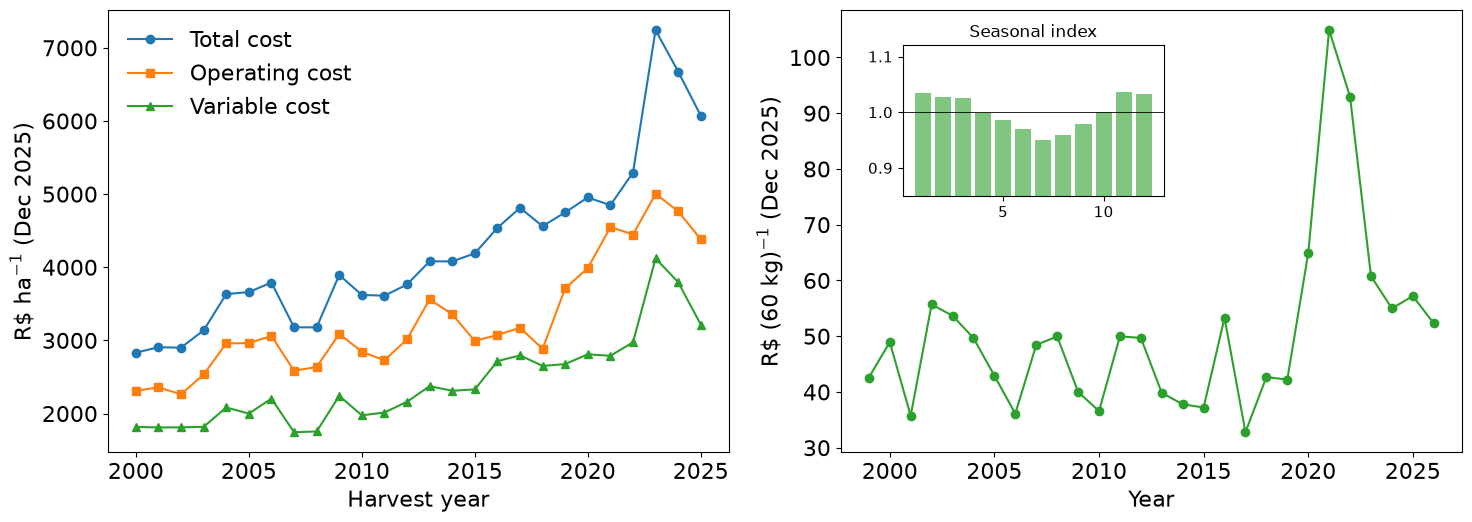

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5.5))
a1.plot(custos.index, custos["custo_total_real_ha"], "o-", label="Total cost")
a1.plot(custos.index, custos["custo_operacional_real_ha"], "s-", label="Operating cost")
a1.plot(custos.index, custos["custo_var_real_ha"], "^-", label="Variable cost")
a1.set(xlabel="Harvest year", ylabel=r"R\$ ha$^{-1}$ (Dec 2025)")
a1.legend(frameon=False)
anual = precos.groupby("ano")["preco_real_60kg"].mean()
a2.plot(anual.index, anual.values, "o-", color="tab:green", label="Annual mean")
a2.set(xlabel="Year", ylabel=r"R\$ (60 kg)$^{-1}$ (Dec 2025)")
ax_in = a2.inset_axes([0.10, 0.58, 0.42, 0.34])
ax_in.bar(indice_sazonal.index, indice_sazonal["mean"], color="tab:green", alpha=0.6)
ax_in.axhline(1, color="k", lw=0.6)
ax_in.set_ylim(0.85, 1.12)
ax_in.set_title("Seasonal index", fontsize=12)
ax_in.tick_params(labelsize=11)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_custos_precos.png", dpi=300)